In [ ]:
import gc
import joblib

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import optuna
from optuna.visualization import plot_optimization_history

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


import tensorflow.keras.backend as K

from tensorflow.keras import layers

import tensorflow as tf
from tensorflow.keras import layers
import keras
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
from tensorflow.keras.callbacks import EarlyStopping


<h2>Methods</h2>

In [ ]:
# method to automatically downcast data types for a df
def optimize_dataframe_dtypes(df):
    df_opt = df.copy()

    for col in df_opt.columns:
        if col.startswith(("cat__", "encoded__")):
            # One-hot encoded -> int8
            df_opt[col] = df_opt[col].round().astype(np.int8)

        elif col.startswith("num__"):
            if pd.api.types.is_integer_dtype(df_opt[col]):
                df_opt[col] = pd.to_numeric(df_opt[col], downcast="integer")
            elif pd.api.types.is_float_dtype(df_opt[col]):
                df_opt[col] = pd.to_numeric(df_opt[col], downcast="float")

    return df_opt

In [ ]:
# HPO ranges for Optuna trials
trial_suggestions = {
    # Number of neurons in the first hidden layer
    "units_l0": trial.suggest_int("units_l0", 32, 256, step=32),
    # Helps control overfitting by randomly dropping neurons during training
    "dropout_l0": trial.suggest_float("dropout_l0", 0.1, 0.5),
    # L2 regularization strength for first hidden layer (log scale search)
    "l2_l0": trial.suggest_float("l2_l0", 1e-6, 1e-1, log=True),

    # Number of neurons in the second hidden layer 
    "units_l1": trial.suggest_int("units_l1", 32, 256, step=32),
    # Dropout for second layer
    "dropout_l1": trial.suggest_float("dropout_l1", 0.1, 0.5),
    # L2 regularization for second hidden layer
    "l2_l1": trial.suggest_float("l2_l1", 1e-6, 1e-1, log=True),

    # Learning rate for the AdamOptimizer
    "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),

    # Number of samples per gradient update step
    "batch_size": trial.suggest_categorical("batch_size", [32, 64])
}


In [ ]:
# Build simple Keras model for Optuna trial
def build_model(trial, input_dim):
    model = tf.keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))

    # First Hidden Layer
    units_l0 = trial.suggest_int("units_l0", 32, 128, step=32)
    model.add(layers.Dense(
        units_l0,
        activation='relu',
        kernel_regularizer=tf.keras.regularizers.l2(
            trial.suggest_float("l2_l0", 1e-6, 1e-1, log=True)
        )
    ))
    model.add(layers.Dropout(trial.suggest_float("dropout_l0", 0.1, 0.5)))

    # Second Hidden Layer
    units_l1 = trial.suggest_int("units_l1", 32, 128, step=32)
    model.add(layers.Dense(
        units_l1,
        activation='relu',
        kernel_regularizer=tf.keras.regularizers.l2(
            trial.suggest_float("l2_l1", 1e-6, 1e-1, log=True)
        )
    ))
    model.add(layers.Dropout(trial.suggest_float("dropout_l1", 0.1, 0.5)))

    # Output Layer
    model.add(layers.Dense(1))

    # Compile Model
    learning_rate = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='mean_squared_error',
        metrics=['mean_squared_error']
    )

    return model

def objective(trial):
    try:
        # Use TimeSeriesSplit for CV
        tscv = TimeSeriesSplit(n_splits=3)
        val_rmse_scores = []
        val_r2_scores = []
        
        # Keras callbacks for early stopping (stop after 5 iterations without improvement)
        early_stop = tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True
        )
    
        # Time-Series validation loop for each fold
        for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train_sampled)):
            X_tr, X_val = X_train_sampled.iloc[train_idx], X_train_sampled.iloc[val_idx]
            y_tr, y_val = y_train_sampled.iloc[train_idx], y_train_sampled.iloc[val_idx]
    
            model = build_model(trial, input_dim=X_train_sampled.shape[1])

            print(f"Starting Trial {trial.number} Fold {fold + 1}")
            model.fit(
                X_tr,
                y_tr,
                validation_data=(X_val, y_val),
                epochs=30,
                batch_size=trial.suggest_categorical("batch_size", [16, 32]),
                callbacks=[early_stop],
                verbose=0 
            )
        
            y_pred = model.predict(X_val).squeeze()
            
            rmse = np.sqrt(mean_squared_error(y_val, y_pred))
            val_rmse_scores.append(rmse)
            r2 = r2_score(y_val, y_pred)
            val_r2_scores.append(r2)
            print(f"Trial {trial.number} Fold {fold + 1} RMSE: {rmse:.4f} R2: {r2:.4f}")

            # Clear some memory from this trial
            tf.keras.backend.clear_session()
            del model
            gc.collect()
    
    
        avg_rmse = np.mean(val_rmse_scores)
        avg_r2 = np.mean(val_r2_scores)
                
        print(f"Trial {trial.number} avg RMSE: {avg_rmse:.4f} avg R2: {avg_r2:.4f}")
    
        return avg_rmse
    except Exception as e:
        print(f"Trial {trial.number} failed due to: {e}")
        return float("inf")

In [ ]:
# Build simple Keras Model with specified params (after Optuna optimization)
def build_final_model(input_dim, best_params):
    model = tf.keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))

    # First Hidden Layer
    model.add(layers.Dense(
        best_params["units_l0"],
        activation='relu',
        kernel_regularizer=tf.keras.regularizers.l2(best_params["l2_l0"])
    ))
    model.add(layers.Dropout(best_params["dropout_l0"]))

    # Second Hidden Layer
    model.add(layers.Dense(
        best_params["units_l1"],
        activation='relu',
        kernel_regularizer=tf.keras.regularizers.l2(best_params["l2_l1"])
    ))
    model.add(layers.Dropout(best_params["dropout_l1"]))

    # Output Layer
    model.add(layers.Dense(1))

    # Compile Model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=best_params["lr"]),
        loss='mean_squared_error',
        metrics=['mean_squared_error']
    )

    return model


<h1>Modeling (NY)</h1>

- for NY, we preprocess the data and optimize NOx, SO2, and CO2 models without and with lags using 20 Optuna trials and evaluate it by training with 2019-2023 data and testing on 2024 data five separate times and taking the average performance
- ran into problems with memory which is why data is downsampled and studies are manually resumed if a study crashed midway through (-> studies were run up to 20 successful trials)

In [4]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'NOx Mass (lbs)': 'float32',
    'NOx Mass Measure Indicator': 'string',
    'NOx Rate (lbs/mmBtu)': 'float32',
    'NOx Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'NOx Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'NOx Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32',
    'Temperature (F)': 'float32'
}

<h2>No Lags</h2>

<h3>NOx</h3>

<h4>Preprocessing</h4>

In [5]:
campd_df = pd.read_csv("Data/NY/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [ ]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) 

target_variable = "NOx Mass (lbs)"

In [8]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

# instead of imputing with median, we remove nan cols/rows (Summer Capacity has too many nans to impute, for lower nan values we remove the rows)

Gross Load (MW)              4.674485
Latitude                    11.055066
Longitude                   11.055066
Nameplate Capacity (MWe)    11.055066
hourly_capacity_factor       5.678980
hourly_ramping_factor       15.730771
Summer Capacity (MW)        59.033506
Winter Capacity (MW)        59.033506
Minimum Load (MW)           59.033506
Temperature (F)              1.723858
dtype: float64

In [11]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3197828, 95), New shape: (2666036, 95)
Change in total rows: -531792


In [12]:
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [13]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [ ]:
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

<h4>HPO</h4>

In [ ]:
study = optuna.create_study(
    study_name="30_07_00_20_MLP_NY_NOx",
    storage="sqlite:///optuna_studies.db",
    #load_if_exists=True,
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

In [ ]:
study = optuna.load_study(
    study_name="30_07_00_20_MLP_NY_NOx",
    storage="sqlite:///optuna_studies.db"
)

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)

Best params: {'units_l0': 128, 'l2_l0': 2.7512241848872438e-05, 'dropout_l0': 0.1179232686745594, 'units_l1': 96, 'l2_l1': 1.5274817834439256e-05, 'dropout_l1': 0.2808788230410229, 'lr': 0.0004934490971235503, 'batch_size': 16}
Best value (RMSE): 13.569229070344798


<h4>Evaluation</h4>

In [ ]:
best_r2 = -np.inf
best_model = None
best_run_index = -1

# Lists to store results for all runs
r2_scores = []
rmse_scores = []
nrmse_scores = []
models = []

# Load best parameters from Optuna
study = optuna.load_study(
    study_name="30_07_00_20_MLP_NY_NOx",
    storage="sqlite:///optuna_studies.db"
)
best_params = study.best_trial.params

# Repeat training 5 times
for i in range(5):
    print(f"\nTraining Run {i+1}")

    tf.keras.backend.clear_session()

    model = build_final_model(X_train.shape[1], best_params)

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    sample_indices = X_train.sample(frac=0.2, random_state=42).index
    X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
    y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

    # Since the MLP here is so sensitive to the number of epochs, we use a validation split for training the full model
    # -> slight tradeoff because we remove some more recent training data, but use an optimal epoch
    # 70/30 split for train/val
    split_idx = int(len(X_train_sampled) * 0.7)
    X_tr, X_val = X_train_sampled.iloc[:split_idx], X_train_sampled.iloc[split_idx:]
    y_tr, y_val = y_train_sampled.iloc[:split_idx], y_train_sampled.iloc[split_idx:]

    # Fit model 
    model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=best_params["batch_size"],
        callbacks=[early_stop],
        verbose=1  
    )

    # Predict on test
    y_pred = model.predict(X_test)
    y_pred[y_pred < 0] = 0 

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    nrmse = rmse/np.std(y_test)
    print(f"Run {i+1} — Test R²: {r2:.4f} | RMSE: {rmse:.2f}")

    # Append results and model
    r2_scores.append(r2)
    rmse_scores.append(rmse)
    nrmse_scores.append(nrmse)
    models.append(model)

    # Save best model
    if r2 > best_r2:
        best_r2 = r2
        best_model = model
        best_run_index = i


Summary over all runs:
Mean R²: 0.9402 ± 0.0036
Mean RMSE: 15.4686 ± 0.4660
13505/13505 ━━━━━━━━━━━━━━━━━━━━ 5s 394us/step
R^2 Score: 0.9440
Mean Squared Error (MSE): 224.0643
Root Mean Squared Error (RMSE): 14.9688
Normalized RMSE (by std): 0.2365


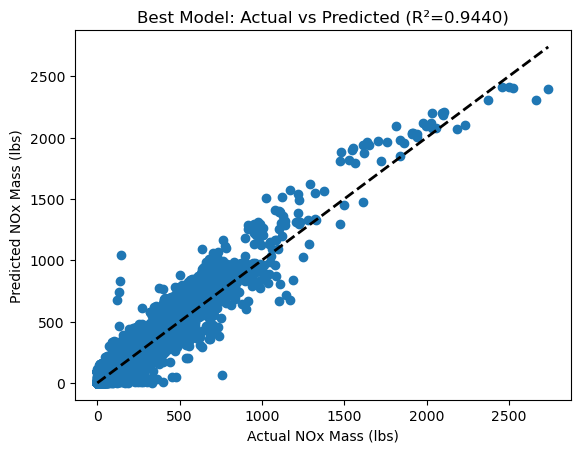

In [99]:
print("\nSummary over all runs:")
print(f"Mean R²: {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}")
print(f"Mean RMSE: {np.mean(rmse_scores):.4f} ± {np.std(rmse_scores):.4f}")
#print(f"Mean nRMSE: {np.mean(nrmse_scores):.4f} ± {np.std(nrmse_scores):.4f}")

#best_model.save('Trained Models/MLP_HPO_NY_NOx_No_lags.keras') 

#best_model = keras.models.load_model('Trained Models/MLP_HPO_NY_NOx_No_lags.keras')

# Plot best model predictions
y_pred = best_model.predict(X_test).squeeze()
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.title(f"Best Model: Actual vs Predicted (R²={best_r2:.4f})")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [ ]:
# manually calculate mean nRMSE 
15.4686/np.std(y_test)

0.24435247168660365

<h3>SO2</h3>

<h4>Preprocessing</h4>

In [18]:
campd_df = pd.read_csv("Data/NY/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [19]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols) 

target_variable = "SO2 Mass (lbs)"

In [13]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

Gross Load (MW)              5.967985
Latitude                    10.302394
Longitude                   10.302394
Nameplate Capacity (MWe)    10.302394
hourly_capacity_factor       6.935827
hourly_ramping_factor       16.271541
Summer Capacity (MW)        58.785922
Winter Capacity (MW)        58.785922
Minimum Load (MW)           58.785922
Temperature (F)              1.696861
dtype: float64

In [20]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3443122, 80), New shape: (2850950, 80)
Change in total rows: -592172


In [21]:
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (SO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [22]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [12]:
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

<h4>HPO</h4>

In [ ]:
study = optuna.create_study(
    study_name="30_07_10_15_MLP_NY_SO2",
    storage="sqlite:///optuna_studies.db",
    #load_if_exists=True,
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)


In [7]:
study = optuna.load_study(
    study_name="30_07_10_15_MLP_NY_SO2",
    storage="sqlite:///optuna_studies.db"
)

print(study.best_trial.params)


{'units_l0': 128, 'l2_l0': 0.0016254237571609851, 'dropout_l0': 0.26164012458779606, 'units_l1': 64, 'l2_l1': 1.960789654334785e-06, 'dropout_l1': 0.36962338821648294, 'lr': 0.001525338457357143, 'batch_size': 32}


<h4>Evaluation</h4>

In [ ]:
best_r2 = -np.inf
best_model = None
best_run_index = -1

# Lists to store results for all runs
r2_scores = []
rmse_scores = []
nrmse_scores = []
models = []

# Load best parameters from Optuna
study = optuna.load_study(
    study_name="30_07_10_15_MLP_NY_SO2",
    storage="sqlite:///optuna_studies.db"
)
best_params = study.best_trial.params

# Repeat training 5 times
for i in range(5):
    print(f"\nTraining Run {i+1}")

    tf.keras.backend.clear_session()

    model = build_final_model(X_train.shape[1], best_params)

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    sample_indices = X_train.sample(frac=0.2, random_state=42).index
    X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
    y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

    # Since the MLP here is so sensitive to the number of epochs, we use a validation split for training the full model
    # -> slight tradeoff because we remove some more recent training data, but use an optimal epoch
    # 70/30 split for train/val
    split_idx = int(len(X_train_sampled) * 0.7)
    X_tr, X_val = X_train_sampled.iloc[:split_idx], X_train_sampled.iloc[split_idx:]
    y_tr, y_val = y_train_sampled.iloc[:split_idx], y_train_sampled.iloc[split_idx:]

    # Fit model 
    model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=best_params["batch_size"],
        callbacks=[early_stop],
        verbose=1  
    )

    # Predict on test
    y_pred = model.predict(X_test)
    y_pred[y_pred < 0] = 0 

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    nrmse = rmse/np.std(y_test)
    print(f"Run {i+1} — Test R²: {r2:.4f} | RMSE: {rmse:.2f}")

    # Append results and model
    r2_scores.append(r2)
    rmse_scores.append(rmse)
    nrmse_scores.append(nrmse)
    models.append(model)

    # Save best model
    if r2 > best_r2:
        best_r2 = r2
        best_model = model
        best_run_index = i


Best model from run 1 saved with Test R²: 0.7013

Summary over all runs:
Mean R²: 0.5751 ± 0.0812
Mean RMSE: 35.9690 ± 3.5075
Mean nRMSE: 0.6488 ± 0.0633
14505/14505 ━━━━━━━━━━━━━━━━━━━━ 6s 397us/step
R^2 Score: 0.7013
Mean Squared Error (MSE): 918.0203
Root Mean Squared Error (RMSE): 30.2988
Normalized RMSE (by std): 0.5465


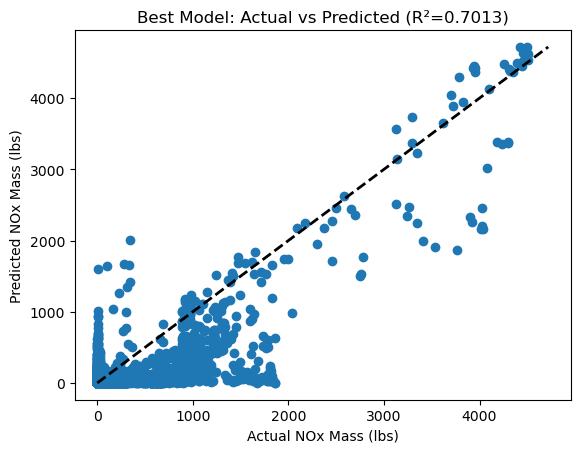

In [23]:
print(f"\nBest model from run {best_run_index + 1} saved with Test R²: {best_r2:.4f}")

print("\nSummary over all runs:")
print(f"Mean R²: {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}")
print(f"Mean RMSE: {np.mean(rmse_scores):.4f} ± {np.std(rmse_scores):.4f}")
print(f"Mean nRMSE: {np.mean(nrmse_scores):.4f} ± {np.std(nrmse_scores):.4f}")

best_model.save('Trained Models/MLP_HPO_NY_SO2_No_Lags.keras') 

#best_model = keras.models.load_model('Trained Models/MLP_HPO_NY_NOx_No_Lags.keras')

# Plot best model predictions
y_pred = best_model.predict(X_test).squeeze()
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.title(f"Best Model: Actual vs Predicted (R²={best_r2:.4f})")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

# Extreme variance! 

<h3>CO2</h3>

<h4>Preprocessing</h4>

In [7]:
campd_df = pd.read_csv("Data/NY/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [8]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 
                'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) #+ lag_cols # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

In [18]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

Gross Load (MW)              6.013790
Latitude                    10.389658
Longitude                   10.389658
Nameplate Capacity (MWe)    10.389658
hourly_capacity_factor       6.989830
hourly_ramping_factor       16.404619
Summer Capacity (MW)        58.477659
Winter Capacity (MW)        58.477659
Minimum Load (MW)           58.477659
Temperature (F)              1.702535
dtype: float64

In [9]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3414203, 80), New shape: (2822490, 80)
Change in total rows: -591713


In [10]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 
                'hourly_capacity_factor',
                'hourly_ramping_factor',
                # 'Summer Capacity (MW)',
                # 'Winter Capacity (MW)', 
                # 'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) #+ lag_cols # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [11]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [12]:
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

<h4>HPO</h4>

In [ ]:
study = optuna.create_study(
    study_name="30_07_XX_XX_MLP_NY_CO2",
    storage="sqlite:///optuna_studies.db",
    #load_if_exists=True,
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)

In [8]:
study = optuna.load_study(
    study_name="30_07_XX_XX_MLP_NY_CO2",
    storage="sqlite:///optuna_studies.db"
)

study.best_params

{'units_l0': 96,
 'l2_l0': 2.1894103709617406e-06,
 'dropout_l0': 0.11405773142399739,
 'units_l1': 64,
 'l2_l1': 1.1881199872798445e-06,
 'dropout_l1': 0.11732548105506496,
 'lr': 0.0004039270776636616,
 'batch_size': 32}

<h4>Evaluation</h4>

In [ ]:
best_r2 = -np.inf
best_model = None
best_run_index = -1

# Lists to store results for all runs
r2_scores = []
rmse_scores = []
nrmse_scores = []
models = []

# Load best parameters from Optuna
study = optuna.load_study(
    study_name="30_07_XX_XX_MLP_NY_CO2",
    storage="sqlite:///optuna_studies.db"
)
best_params = study.best_trial.params

# Repeat training 5 times
for i in range(5):
    print(f"\nTraining Run {i+1}")

    tf.keras.backend.clear_session()

    model = build_final_model(X_train.shape[1], best_params)

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    sample_indices = X_train.sample(frac=0.2, random_state=42).index
    X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
    y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

    # Since the MLP here is so sensitive to the number of epochs, we use a validation split  for training the full model
    # -> slight tradeoff because we remove some more recent training data, but use an optimal epoch
    # 70/30 split for train/val
    split_idx = int(len(X_train_sampled) * 0.7)
    X_tr, X_val = X_train_sampled.iloc[:split_idx], X_train_sampled.iloc[split_idx:]
    y_tr, y_val = y_train_sampled.iloc[:split_idx], y_train_sampled.iloc[split_idx:]

    # Fit model 
    model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=best_params["batch_size"],
        callbacks=[early_stop],
        verbose=1  
    )

    # Predict on test
    y_pred = model.predict(X_test)
    y_pred[y_pred < 0] = 0 

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    nrmse = rmse/np.std(y_test)
    print(f"Run {i+1} — Test R²: {r2:.4f} | RMSE: {rmse:.2f}")

    # Append results and model
    r2_scores.append(r2)
    rmse_scores.append(rmse)
    nrmse_scores.append(nrmse)
    models.append(model)

    # Save best model
    if r2 > best_r2:
        best_r2 = r2
        best_model = model
        best_run_index = i


Best model from run 2 saved with Test R²: 0.9976

Summary over all runs:
Mean R²: 0.9971 ± 0.0003
Mean RMSE: 3.0234 ± 0.1471
Mean nRMSE: 0.0535 ± 0.0026
14362/14362 ━━━━━━━━━━━━━━━━━━━━ 6s 402us/step
R^2 Score: 0.9976
Mean Squared Error (MSE): 7.6242
Root Mean Squared Error (RMSE): 2.7612
Normalized RMSE (by std): 0.0488


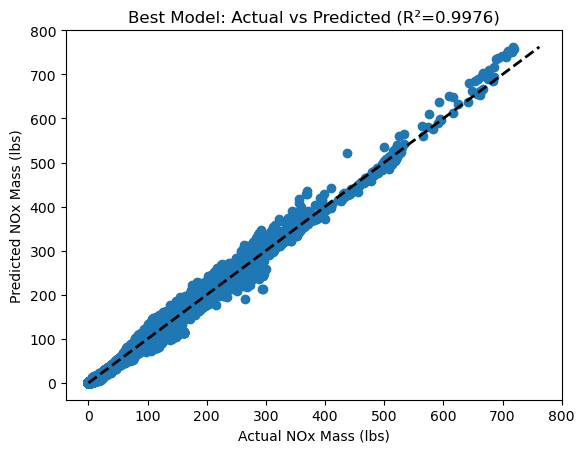

In [14]:
print(f"\nBest model from run {best_run_index + 1} saved with Test R²: {best_r2:.4f}")

print("\nSummary over all runs:")
print(f"Mean R²: {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}")
print(f"Mean RMSE: {np.mean(rmse_scores):.4f} ± {np.std(rmse_scores):.4f}")
print(f"Mean nRMSE: {np.mean(nrmse_scores):.4f} ± {np.std(nrmse_scores):.4f}")

best_model.save('Trained Models/MLP_HPO_NY_CO2_No_Lags.keras') 

#best_model = keras.models.load_model('Trained Models/MLP_HPO_NY_CO2_No_Lagsx.keras')

# Plot best model predictions
y_pred = best_model.predict(X_test).squeeze()
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.title(f"Best Model: Actual vs Predicted (R²={best_r2:.4f})")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h2>With Lags</h2>

<h3>NOx</h3>

<h4>Preprocessing</h4>

In [7]:
campd_df = pd.read_csv("Data/NY/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [8]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3197828, 95), New shape: (2666036, 95)
Change in total rows: -531792


In [9]:
# features
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]  + lag_cols # include lags

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols)

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [10]:
X_train = X_train.dropna(axis=0, how='any')  # drop rows with any NaN values (lags)
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

In [11]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [12]:
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

<h4>HPO</h4>

In [ ]:
study = optuna.create_study(
    study_name="30_07_17_40_MLP_NY_NOx_WITH_LAGS",
    storage="sqlite:///optuna_studies.db",
    #load_if_exists=True,
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)

<h4>Evaluation</h4>

In [ ]:
best_r2 = -np.inf
best_model = None
best_run_index = -1

# Lists to store results for all runs
r2_scores = []
rmse_scores = []
nrmse_scores = []
models = []

# Load best parameters from Optuna
study = optuna.load_study(
    study_name="30_07_17_40_MLP_NY_NOx_WITH_LAGS",
    storage="sqlite:///optuna_studies.db"
)
best_params = study.best_trial.params

# Repeat training 5 times
for i in range(5):
    print(f"\nTraining Run {i+1}")

    tf.keras.backend.clear_session()

    model = build_final_model(X_train.shape[1], best_params)

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    sample_indices = X_train.sample(frac=0.2, random_state=42).index
    X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
    y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

    # Since the MLP here is so sensitive to the number of epochs, we use a validation split  for training the full model
    # -> slight tradeoff because we remove some more recent training data, but use an optimal epoch
    # 70/30 split for train/val
    split_idx = int(len(X_train_sampled) * 0.7)
    X_tr, X_val = X_train_sampled.iloc[:split_idx], X_train_sampled.iloc[split_idx:]
    y_tr, y_val = y_train_sampled.iloc[:split_idx], y_train_sampled.iloc[split_idx:]

    # Fit model 
    model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=best_params["batch_size"],
        callbacks=[early_stop],
        verbose=1  
    )

    # Predict on test
    y_pred = model.predict(X_test)
    y_pred[y_pred < 0] = 0 

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    nrmse = rmse/np.std(y_test)
    print(f"Run {i+1} — Test R²: {r2:.4f} | RMSE: {rmse:.2f}")

    # Append results and model
    r2_scores.append(r2)
    rmse_scores.append(rmse)
    nrmse_scores.append(nrmse)
    models.append(model)

    # Save best model
    if r2 > best_r2:
        best_r2 = r2
        best_model = model
        best_run_index = i


Best model from run 1 saved with Test R²: 0.9850

Summary over all runs:
Mean R²: 0.9842 ± 0.0007
Mean RMSE: 7.9621 ± 0.1747
Mean nRMSE: 0.1258 ± 0.0028
13505/13505 ━━━━━━━━━━━━━━━━━━━━ 6s 406us/step
R^2 Score: 0.9850
Mean Squared Error (MSE): 60.1353
Root Mean Squared Error (RMSE): 7.7547
Normalized RMSE (by std): 0.1225


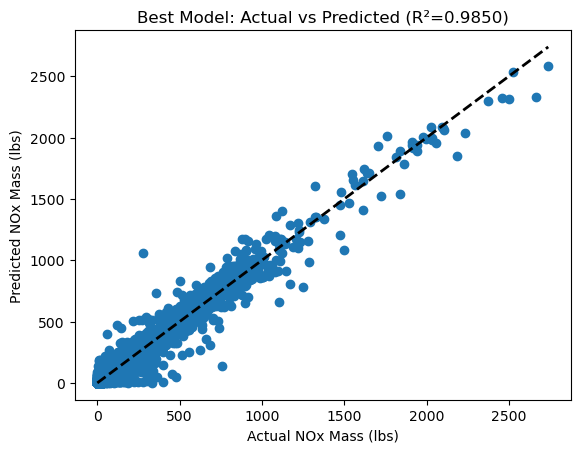

In [14]:
print(f"\nBest model from run {best_run_index + 1} saved with Test R²: {best_r2:.4f}")

print("\nSummary over all runs:")
print(f"Mean R²: {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}")
print(f"Mean RMSE: {np.mean(rmse_scores):.4f} ± {np.std(rmse_scores):.4f}")
print(f"Mean nRMSE: {np.mean(nrmse_scores):.4f} ± {np.std(nrmse_scores):.4f}")

best_model.save('Trained Models/MLP_HPO_NY_NOx_With_Lags.keras') 

#best_model = keras.models.load_model('Trained Models/MLP_HPO_NY_CO2_No_Lagsx.keras')

# Plot best model predictions
y_pred = best_model.predict(X_test).squeeze()
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.title(f"Best Model: Actual vs Predicted (R²={best_r2:.4f})")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h3>SO2</h3>

<h4>Preprocessing</h4>

In [8]:
campd_df = pd.read_csv("Data/NY/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [9]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3443122, 80), New shape: (2850950, 80)
Change in total rows: -592172


In [10]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]


num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols) 

target_variable = "SO2 Mass (lbs)"


# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [11]:
X_train = X_train.dropna(axis=0, how='any')  # drop rows with any NaN values (lags)
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

In [12]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [13]:
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

<h4>HPO</h4>

In [ ]:
study = optuna.create_study(
    study_name="30_07_XX_XX_MLP_NY_SO2_WITH_LAGS",
    storage="sqlite:///optuna_studies.db",
    #load_if_exists=True,
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)

<h4>Evaluation</h4>

In [ ]:
best_r2 = -np.inf
best_model = None
best_run_index = -1

# Lists to store results for all runs
r2_scores = []
rmse_scores = []
nrmse_scores = []
models = []

# Load best parameters from Optuna
study = optuna.load_study(
    study_name="30_07_XX_XX_MLP_NY_SO2_WITH_LAGS",
    storage="sqlite:///optuna_studies.db"
)
best_params = study.best_trial.params

# Repeat training 5 times
for i in range(5):
    print(f"\nTraining Run {i+1}")

    tf.keras.backend.clear_session()

    model = build_final_model(X_train.shape[1], best_params)

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    sample_indices = X_train.sample(frac=0.2, random_state=42).index
    X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
    y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

    # Since the MLP here is so sensitive to the number of epochs, we use a validation split  for training the full model
    # -> slight tradeoff because we remove some more recent training data, but use an optimal epoch
    # 70/30 split for train/val
    split_idx = int(len(X_train_sampled) * 0.7)
    X_tr, X_val = X_train_sampled.iloc[:split_idx], X_train_sampled.iloc[split_idx:]
    y_tr, y_val = y_train_sampled.iloc[:split_idx], y_train_sampled.iloc[split_idx:]

    # Fit model 
    model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=best_params["batch_size"],
        callbacks=[early_stop],
        verbose=1  
    )

    # Predict on test
    y_pred = model.predict(X_test)
    y_pred[y_pred < 0] = 0 

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    nrmse = rmse/np.std(y_test)
    print(f"Run {i+1} — Test R²: {r2:.4f} | RMSE: {rmse:.2f}")

    # Append results and model
    r2_scores.append(r2)
    rmse_scores.append(rmse)
    nrmse_scores.append(nrmse)
    models.append(model)

    # Save best model
    if r2 > best_r2:
        best_r2 = r2
        best_model = model
        best_run_index = i


Best model from run 4 saved with Test R²: 0.9819

Summary over all runs:
Mean R²: 0.9761 ± 0.0047
Mean RMSE: 8.5316 ± 0.8417
Mean nRMSE: 0.1539 ± 0.0152
14505/14505 ━━━━━━━━━━━━━━━━━━━━ 6s 398us/step
R^2 Score: 0.9819
Mean Squared Error (MSE): 55.5669
Root Mean Squared Error (RMSE): 7.4543
Normalized RMSE (by std): 0.1345


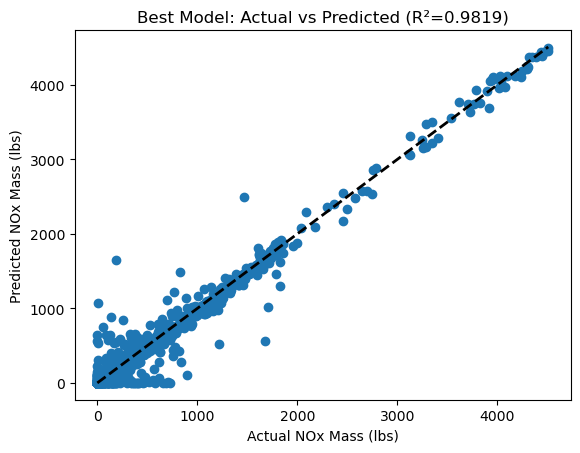

In [15]:
print(f"\nBest model from run {best_run_index + 1} saved with Test R²: {best_r2:.4f}")

print("\nSummary over all runs:")
print(f"Mean R²: {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}")
print(f"Mean RMSE: {np.mean(rmse_scores):.4f} ± {np.std(rmse_scores):.4f}")
print(f"Mean nRMSE: {np.mean(nrmse_scores):.4f} ± {np.std(nrmse_scores):.4f}")

best_model.save('Trained Models/MLP_HPO_NY_SO2_With_Lags.keras') 

#best_model = keras.models.load_model('Trained Models/MLP_HPO_NY_CO2_No_Lagsx.keras')

# Plot best model predictions
y_pred = best_model.predict(X_test).squeeze()
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.title(f"Best Model: Actual vs Predicted (R²={best_r2:.4f})")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h3>CO2</h3>

<h4>Preprocessing</h4>

In [7]:
campd_df = pd.read_csv("Data/NY/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [8]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3414203, 80), New shape: (2822490, 80)
Change in total rows: -591713


In [9]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 
                'hourly_capacity_factor',
                'hourly_ramping_factor',
                # 'Summer Capacity (MW)',
                # 'Winter Capacity (MW)', 
                # 'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols)

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [10]:
X_train = X_train.dropna(axis=0, how='any')  # drop rows with any NaN values (lags)
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

In [11]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [12]:
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

<h4>HPO</h4>

In [ ]:
study = optuna.create_study(
    study_name="31_07_11_30_MLP_NY_CO2_WITH_LAGS",
    storage="sqlite:///optuna_studies.db",
    load_if_exists=True,
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)

<h4>Evaluation</h4>

In [ ]:
best_r2 = -np.inf
best_model = None
best_run_index = -1

# Lists to store results for all runs
r2_scores = []
rmse_scores = []
nrmse_scores = []
models = []

# Load best parameters from Optuna
study = optuna.load_study(
    study_name="31_07_11_30_MLP_NY_CO2_WITH_LAGS",
    storage="sqlite:///optuna_studies.db"
)
best_params = study.best_trial.params

# Repeat training 5 times
for i in range(5):
    print(f"\nTraining Run {i+1}")

    tf.keras.backend.clear_session()

    model = build_final_model(X_train.shape[1], best_params)

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    sample_indices = X_train.sample(frac=0.2, random_state=42).index
    X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
    y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

    # Since the MLP here is so sensitive to the number of epochs, we use a validation split  for training the full model
    # -> slight tradeoff because we remove some more recent training data, but use an optimal epoch
    # 70/30 split for train/val
    split_idx = int(len(X_train_sampled) * 0.7)
    X_tr, X_val = X_train_sampled.iloc[:split_idx], X_train_sampled.iloc[split_idx:]
    y_tr, y_val = y_train_sampled.iloc[:split_idx], y_train_sampled.iloc[split_idx:]

    # Fit model 
    model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=best_params["batch_size"],
        callbacks=[early_stop],
        verbose=1  
    )

    # Predict on test
    y_pred = model.predict(X_test)
    y_pred[y_pred < 0] = 0 

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    nrmse = rmse/np.std(y_test)
    print(f"Run {i+1} — Test R²: {r2:.4f} | RMSE: {rmse:.2f}")

    # Append results and model
    r2_scores.append(r2)
    rmse_scores.append(rmse)
    nrmse_scores.append(nrmse)
    models.append(model)

    # Save best model
    if r2 > best_r2:
        best_r2 = r2
        best_model = model
        best_run_index = i


Best model from run 1 saved with Test R²: 0.9987

Summary over all runs:
Mean R²: 0.9979 ± 0.0009
Mean RMSE: 2.5453 ± 0.5570
Mean nRMSE: 0.0450 ± 0.0099
14362/14362 ━━━━━━━━━━━━━━━━━━━━ 6s 429us/step
R^2 Score: 0.9987
Mean Squared Error (MSE): 4.0328
Root Mean Squared Error (RMSE): 2.0082
Normalized RMSE (by std): 0.0355


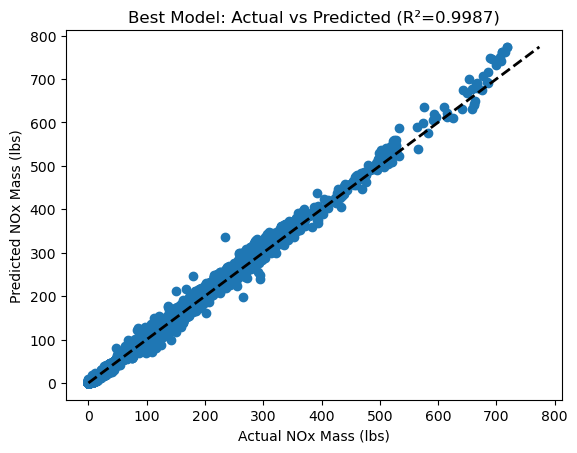

In [14]:
print(f"\nBest model from run {best_run_index + 1} saved with Test R²: {best_r2:.4f}")

print("\nSummary over all runs:")
print(f"Mean R²: {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}")
print(f"Mean RMSE: {np.mean(rmse_scores):.4f} ± {np.std(rmse_scores):.4f}")
print(f"Mean nRMSE: {np.mean(nrmse_scores):.4f} ± {np.std(nrmse_scores):.4f}")

best_model.save('Trained Models/MLP_HPO_NY_CO2_With_Lags.keras') 

#best_model = keras.models.load_model('Trained Models/MLP_HPO_NY_CO2_No_Lagsx.keras')

# Plot best model predictions
y_pred = best_model.predict(X_test).squeeze()
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.title(f"Best Model: Actual vs Predicted (R²={best_r2:.4f})")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h2>Visualizations</h2>

- some selected optuna history plots of optimizations (show value of objective function across studies -> RMSE)
- note that trials numbers can exceed 20 if previous ones crashed due to memory issues. total of successful trials always sums up to 20 though.

In [12]:
# NOx no lags

study = optuna.load_study(
    study_name="30_07_00_20_MLP_NY_NOx",
    storage="sqlite:///optuna_studies.db"
)

opt_history = plot_optimization_history(study)
opt_history.show()


In [13]:
# CO2 no lags

study = optuna.load_study(
    study_name="30_07_XX_XX_MLP_NY_CO2",
    storage="sqlite:///optuna_studies.db"
)

opt_history = plot_optimization_history(study)
opt_history.show()


In [15]:
# SO2 no lags

study = optuna.load_study(
    study_name="30_07_10_15_MLP_NY_SO2",
    storage="sqlite:///optuna_studies.db"
)

opt_history = plot_optimization_history(study)
opt_history.show()

In [14]:
# NOx with lags

study = optuna.load_study(
    study_name="30_07_17_40_MLP_NY_NOx_WITH_LAGS",
    storage="sqlite:///optuna_studies.db"
)

opt_history = plot_optimization_history(study)
opt_history.show()
